# Pest Control Comparison

How do observed insect counts differ by spray?

Data: [datasets/InsectSprays](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/InsectSprays.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Lower counts indicate better observed control; experimental context limits transfer.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Pest Control Comparison',
 'executed_utc': '2026-11-21T10:14:12.057336+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/InsectSprays.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/InsectSprays.html',
 'sha256': 'd2957ac85b1cb22230d244e0cd06f41280cd7e918a0032c8c0d7578b9f53bfe8',
 'raw_rows': 72,
 'analysis_rows': 72,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,72
1,count,int64,0,0.0,24
2,spray,object,0,0.0,6


## SQL and analysis
Complete-case descriptive comparison of count by spray; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "spray" AS segment, COUNT(*) AS rows_used, AVG("count") AS metric, MIN("count") AS minimum, MAX("count") AS maximum FROM observations GROUP BY "spray" ORDER BY "spray";

The largest observed mean count is 16.667 for F. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,A,12,14.500000,7,23
1,B,12,15.333333,7,21
2,C,12,2.083333,0,7
3,D,12,4.916667,2,12
4,E,12,3.500000,1,6
5,F,12,16.666667,9,26


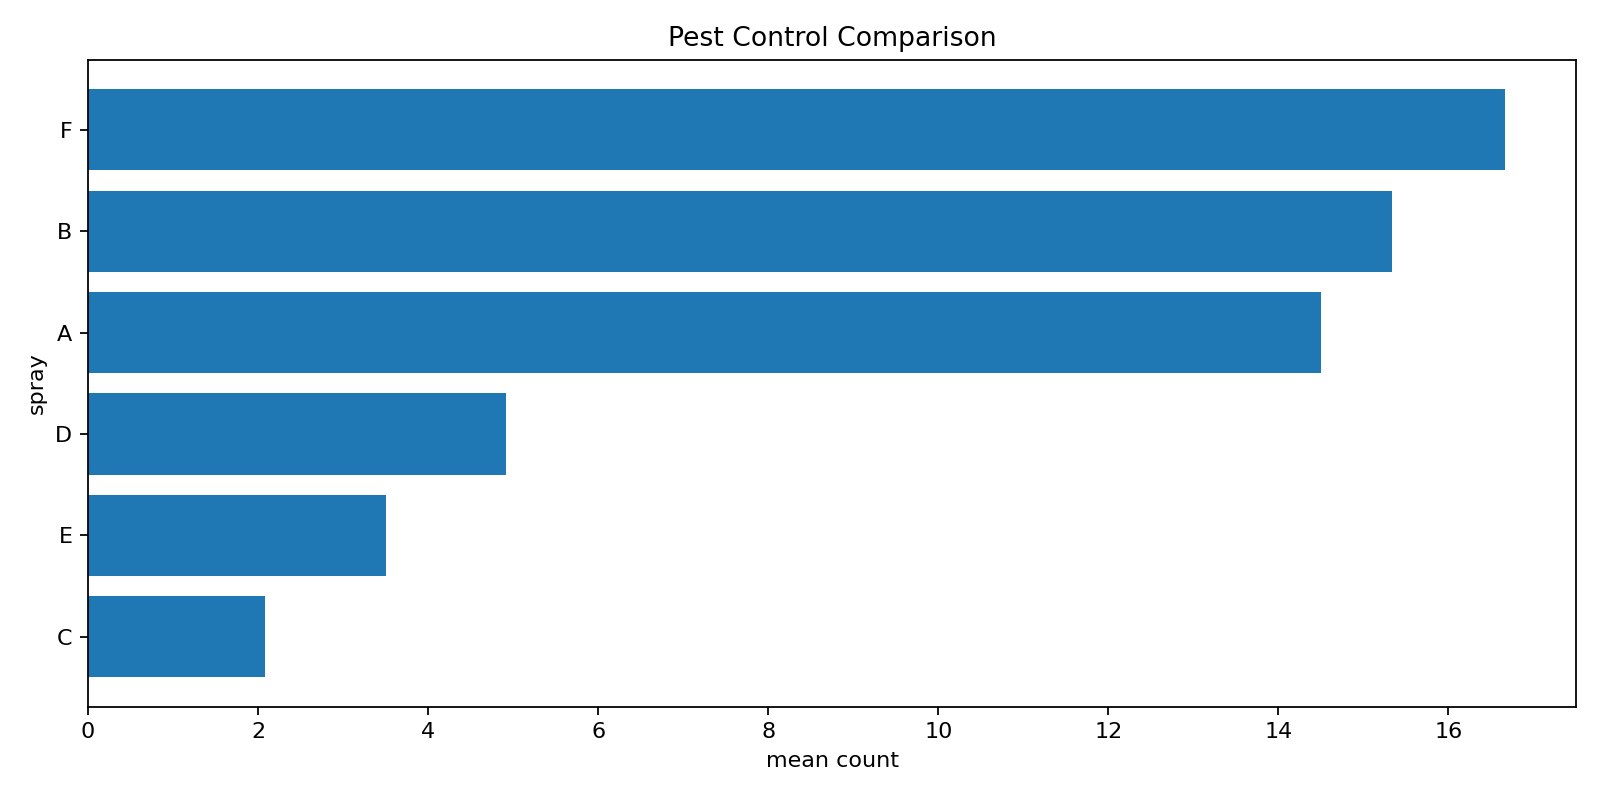

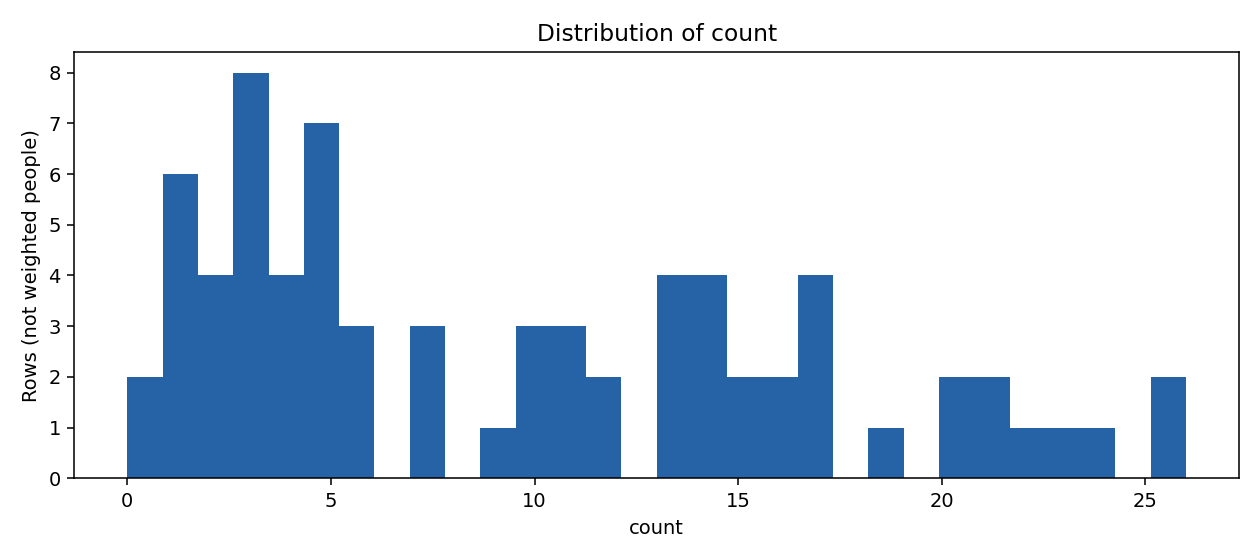

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Lower counts indicate better observed control; experimental context limits transfer.

**Next action:** Compare safety, cost and repeatability before choosing a treatment.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.